Install libraries

In [1]:
!pip install -q pandas numpy scipy scikit-learn matplotlib seaborn streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 36.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 35.4 MB/s eta 0:00:00


Upload datasets

In [2]:
from google.colab import files

uploaded = files.upload()

required_files = ["Books.csv", "Ratings.csv", "Users.csv"]

missing_files = [f for f in required_files if f not in uploaded]

if missing_files:
    raise FileNotFoundError(
        f"Please upload these files: {missing_files}"
    )

print("All three datasets uploaded successfully!")

Saving Books.csv to Books.csv
Saving Ratings.csv to Ratings.csv
Saving Users.csv to Users.csv
All three datasets uploaded successfully!


Load datasets and preprocess

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import os
import subprocess
import time

from scipy.sparse import csr_matrix
from sklearn.model_selection import train_test_split
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import mean_absolute_error, mean_squared_error

Books = pd.read_csv(
    "Books.csv", sep=";", encoding="latin-1",
    on_bad_lines="skip", dtype={"ISBN": str}
)

Ratings = pd.read_csv(
    "Ratings.csv", sep=";", encoding="latin-1",
    on_bad_lines="skip", dtype={"ISBN": str}
)

Users = pd.read_csv(
    "Users.csv", sep=";", encoding="latin-1",
    on_bad_lines="skip"
)

Books.columns = Books.columns.str.strip()
Ratings.columns = Ratings.columns.str.strip()

print("Books dataset:", Books.shape)
print("Ratings dataset:", Ratings.shape)
print("Users dataset:", Users.shape)

display(Books.head())
display(Ratings.head())
display(Users.head())

print("\nMissing values in Books:")
display(Books.isnull().sum())

print("\nMissing values in Ratings:")
display(Ratings.isnull().sum())

print("\nMissing values in Users:")
display(Users.isnull().sum())

Books dataset: (249936, 1)
Ratings dataset: (1149780, 1)
Users dataset: (278698, 1)


,"ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L"
0,"0195153448,Classical Mythology,Mark P. O. Morf..."
1,"0002005018,Clara Callan,Richard Bruce Wright,2..."
2,"0060973129,Decision in Normandy,Carlo D'Este,1..."
3,"0374157065,Flu: The Story of the Great Influen..."
4,"0399135782,The Kitchen God's Wife,Amy Tan,1991..."


,"User-ID,ISBN,Book-Rating"
0,"276725,034545104X,0"
1,"276726,0155061224,5"
2,"276727,0446520802,0"
3,"276729,052165615X,3"
4,"276729,0521795028,6"


,"User-ID,Location,Age"
0,"1,""nyc, new york, usa"","
1,"2,""stockton, california, usa"",18.0"
2,"3,""moscow, yukon territory, russia"","
3,"4,""porto, v.n.gaia, portugal"",17.0"
4,"5,""farnborough, hants, united kingdom"","



Missing values in Books:


,0
"ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L",0



Missing values in Ratings:


,0
"User-ID,ISBN,Book-Rating",0



Missing values in Users:


,0
"User-ID,Location,Age",0


Exploratory Data Analysis (EDA)

/tmp/ipykernel_1500/2932774557.py:7: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  Books = pd.read_csv(


Total ratings: 1149780
Explicit ratings: 433671
Unique users: 105283
Unique books: 340553
Average explicit rating: 7.6


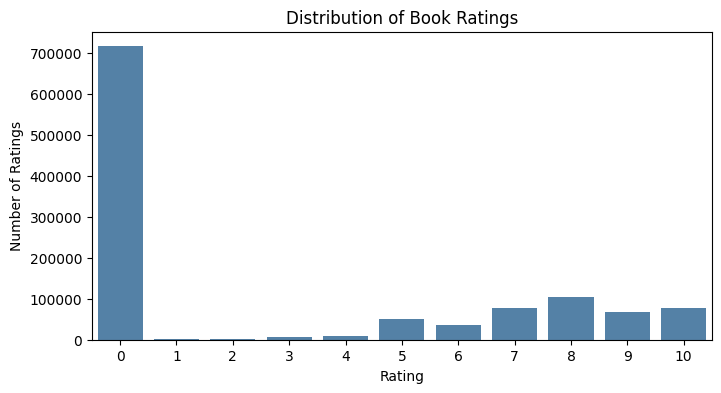

,ISBN,Number of Ratings,Book-Title
0,0316666343,707,The Lovely Bones: A Novel
1,0971880107,581,Wild Animus
2,0385504209,487,The Da Vinci Code
3,0312195516,383,The Red Tent (Bestselling Backlist)
4,0679781587,333,NaN
5,0060928336,320,Divine Secrets of the Ya-Ya Sisterhood: A Novel
6,059035342X,313,Harry Potter and the Sorcerer's Stone (Harry P...
7,0142001740,307,The Secret Life of Bees
8,0446672211,295,Where the Heart Is (Oprah's Book Club (Paperba...
9,044023722X,281,A Painted House


In [4]:
# Re-read the datasets using comma as the separator
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Safely load the datasets with comma separator
Books = pd.read_csv(
    "Books.csv", sep=",", encoding="latin-1",
    on_bad_lines="skip", dtype={"ISBN": str}
)

Ratings = pd.read_csv(
    "Ratings.csv", sep=",", encoding="latin-1",
    on_bad_lines="skip", dtype={"ISBN": str}
)

# Strip whitespaces from column names
Books.columns = Books.columns.str.strip()
Ratings.columns = Ratings.columns.str.strip()

# Keep only valid, explicitly given ratings (1–10)
Ratings["User-ID"] = pd.to_numeric(
    Ratings["User-ID"], errors="coerce"
)
Ratings["Book-Rating"] = pd.to_numeric(
    Ratings["Book-Rating"], errors="coerce"
)
Ratings["ISBN"] = Ratings["ISBN"].astype("string").str.strip()

ratings_clean = Ratings.dropna(
    subset=["User-ID", "ISBN", "Book-Rating"]
).copy()

ratings_clean = ratings_clean[
    (ratings_clean["Book-Rating"] >= 0) &
    (ratings_clean["Book-Rating"] <= 10)
].copy()

ratings_clean["User-ID"] = ratings_clean["User-ID"].astype(int)

ratings_explicit = ratings_clean[
    ratings_clean["Book-Rating"] > 0
].copy()

print("Total ratings:", len(ratings_clean))
print("Explicit ratings:", len(ratings_explicit))
print("Unique users:", ratings_clean["User-ID"].nunique())
print("Unique books:", ratings_clean["ISBN"].nunique())
if len(ratings_explicit) > 0:
    print("Average explicit rating:", round(
        ratings_explicit["Book-Rating"].mean(), 2
    ))

plt.figure(figsize=(8, 4))
sns.countplot(
    data=ratings_clean,
    x="Book-Rating",
    color="steelblue"
)
plt.title("Distribution of Book Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.show()

top_books = (
    ratings_explicit.groupby("ISBN")
    .size()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="Number of Ratings")
    .merge(Books[["ISBN", "Book-Title"]].drop_duplicates("ISBN"),
           on="ISBN", how="left")
)

display(top_books)

Prepare the machine-learning data

In [5]:
ml_data = ratings_explicit[
    ["User-ID", "ISBN", "Book-Rating"]
].copy()

ml_data = ml_data.drop_duplicates(
    subset=["User-ID", "ISBN"], keep="last"
)

# Keep users with at least 5 ratings
user_counts = ml_data.groupby("User-ID").size()
active_users = user_counts[user_counts >= 5].index

ml_data = ml_data[
    ml_data["User-ID"].isin(active_users)
].copy()

# Keep books with at least 5 ratings
book_counts = ml_data.groupby("ISBN").size()
popular_books = book_counts[book_counts >= 5].index

ml_data = ml_data[
    ml_data["ISBN"].isin(popular_books)
].copy()

if ml_data.empty:
    raise ValueError(
        "No data remains after filtering. Check the uploaded datasets."
    )

user_book_matrix = ml_data.pivot_table(
    index="User-ID",
    columns="ISBN",
    values="Book-Rating"
)

total_cells = user_book_matrix.shape[0] * user_book_matrix.shape[1]
sparsity = (
    1 - user_book_matrix.count().sum() / total_cells
) * 100

print("Filtered ratings:", len(ml_data))
print("User-book matrix shape:", user_book_matrix.shape)
print("Matrix sparsity:", round(sparsity, 2), "%")

display(ml_data.head())

Filtered ratings: 141081
User-book matrix shape: (13030, 11234)
Matrix sparsity: 99.9 %


,User-ID,ISBN,Book-Rating
16,276747,0060517794,9
19,276747,0671537458,9
20,276747,0679776818,8
133,276822,0060096195,10
137,276822,0375821813,9


Train the SVD model

In [6]:
import numpy as np, pandas as pd
from scipy.sparse import csr_matrix
from sklearn.model_selection import train_test_split
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ---------- 1. Split: train / validation / test ----------
train_full, test_data = train_test_split(ml_data, test_size=0.20, random_state=42)
train_data, val_data = train_test_split(train_full, test_size=0.125, random_state=42)

# ---------- 2. Biases (CHANGE 1: stop treating missing ratings as 0) ----------
def fit_biases(df, lam_i=10, lam_u=10):
    mu = df["Book-Rating"].mean()
    g = df.groupby("ISBN")["Book-Rating"]
    b_i = (g.sum() - mu * g.count()) / (g.count() + lam_i)            # damped item bias
    d = df.assign(res=df["Book-Rating"] - mu - df["ISBN"].map(b_i))
    g = d.groupby("User-ID")["res"]
    b_u = g.sum() / (g.count() + lam_u)                                # damped user bias
    return mu, b_i, b_u

# ---------- 3. Bias-aware SVD on the RESIDUAL matrix ----------
def fit_svd(df, k):
    mu, b_i, b_u = fit_biases(df)
    users, books = df["User-ID"].unique(), df["ISBN"].unique()
    u_idx = {u: i for i, u in enumerate(users)}; b_idx = {b: i for i, b in enumerate(books)}
    resid = (df["Book-Rating"] - mu - df["ISBN"].map(b_i) - df["User-ID"].map(b_u)).to_numpy()
    R = csr_matrix((resid, (df["User-ID"].map(u_idx), df["ISBN"].map(b_idx))),
                   shape=(len(users), len(books)))
    svd = TruncatedSVD(n_components=min(k, min(R.shape) - 1), random_state=42)
    U = svd.fit_transform(R); V = svd.components_           # U: users x k, V: k x books
    return dict(mu=mu, b_i=b_i, b_u=b_u, u_idx=u_idx, b_idx=b_idx, U=U, V=V,
                users=users, books=books)

def predict_df(m, df):
    """Vectorised rating prediction for a dataframe of (User-ID, ISBN)."""
    ui = df["User-ID"].map(m["u_idx"]); bi = df["ISBN"].map(m["b_idx"])
    pred = m["mu"] + df["User-ID"].map(m["b_u"]).fillna(0).to_numpy() \
                   + df["ISBN"].map(m["b_i"]).fillna(0).to_numpy()
    ok = (ui.notna() & bi.notna()).to_numpy()
    dot = np.zeros(len(df))
    dot[ok] = np.einsum("ij,ji->i", m["U"][ui[ok].astype(int)], m["V"][:, bi[ok].astype(int)])
    return np.clip(pred + dot, 1, 10)

def rmse_mae(y, p): return mean_absolute_error(y, p), float(np.sqrt(mean_squared_error(y, p)))

# ---------- 4. Tune number of latent factors on VALIDATION data (CHANGE 2) ----------
best = None
for k in [10, 20, 50, 100]:
    m = fit_svd(train_data, k)
    mae_v, rmse_v = rmse_mae(val_data["Book-Rating"], predict_df(m, val_data))
    print(f"k={k:>3}  val MAE={mae_v:.3f}  RMSE={rmse_v:.3f}")
    if best is None or rmse_v < best[0]: best = (rmse_v, k)
best_k = best[1]; print("Best k:", best_k)
model = fit_svd(train_full, best_k)            # retrain on train+val, test stays untouched

# ---------- 5. Baselines for comparison (CHANGE 3) ----------
mu, b_i, b_u = fit_biases(train_full)
y = test_data["Book-Rating"].to_numpy()
p_global = np.full(len(y), mu)
p_user   = np.clip(mu + test_data["User-ID"].map(b_u).fillna(0).to_numpy(), 1, 10)
p_item   = np.clip(mu + test_data["ISBN"].map(b_i).fillna(0).to_numpy(), 1, 10)
p_svd    = predict_df(model, test_data)
rows = []
for name, p in [("Global mean", p_global), ("User mean", p_user),
                ("Item mean", p_item), ("Bias-aware SVD", p_svd)]:
    a, r = rmse_mae(y, p); rows.append((name, a, r))
results = pd.DataFrame(rows, columns=["Model", "MAE", "RMSE"]).round(4)
display(results)

# ---------- 6. Top-N recommendations (computed on demand, no 1 GB matrix) ----------
book_info = Books[["ISBN", "Book-Title", "Book-Author"]].drop_duplicates("ISBN").fillna("Unknown")
seen_by_user = train_full.groupby("User-ID")["ISBN"].apply(set).to_dict()
b_i_vec = model["b_i"].reindex(model["books"]).fillna(0).to_numpy()

def top_n_ids(user_id, n=10):
    if user_id not in model["u_idx"]: return None
    u = model["u_idx"][user_id]
    scores = model["mu"] + model["b_u"].get(user_id, 0) + b_i_vec + model["U"][u] @ model["V"]
    scores = np.clip(scores, 1, 10)
    order = np.argsort(-scores)
    out = []
    for j in order:
        if model["books"][j] not in seen_by_user.get(user_id, ()):
            out.append((model["books"][j], scores[j]))
            if len(out) == n: break
    return out

def recommend_books(user_id, n=10):
    r = top_n_ids(user_id, n)
    if r is None: return pd.DataFrame()
    df = pd.DataFrame(r, columns=["ISBN", "Predicted Rating"]).merge(book_info, on="ISBN", how="left")
    df["Predicted Rating"] = df["Predicted Rating"].round(2)
    return df[["ISBN", "Book-Title", "Book-Author", "Predicted Rating"]]

display(recommend_books(int(train_full["User-ID"].iloc[0]), 10))

# ---------- 7. Cosine similarity: similar books (CHANGE 4 - promised in abstract) ----------
B = model["V"].T / (np.linalg.norm(model["V"].T, axis=1, keepdims=True) + 1e-9)   # unit book vectors
def similar_books(isbn, n=10):
    if isbn not in model["b_idx"]: return pd.DataFrame()
    sims = B @ B[model["b_idx"][isbn]]
    top = np.argsort(-sims)[1:n + 1]
    df = pd.DataFrame({"ISBN": model["books"][top], "Cosine Similarity": sims[top].round(3)})
    return df.merge(book_info, on="ISBN", how="left")

# ---------- 8. Precision@K / Recall@K on ALL test users (CHANGE 5) ----------
def precision_recall_at_k(K=10, thr=7):
    rel = test_data[test_data["Book-Rating"] >= thr].groupby("User-ID")["ISBN"].apply(set)
    P, R = [], []
    for uid, relevant in rel.items():
        recs = top_n_ids(uid, K)
        if recs is None: continue
        hit = len({i for i, _ in recs} & relevant)
        P.append(hit / K); R.append(hit / len(relevant))
    return float(np.mean(P)), float(np.mean(R)), len(P)

for K in (5, 10):
    p_k, r_k, n_users = precision_recall_at_k(K)
    print(f"K={K}: Precision={p_k:.4f}  Recall={r_k:.4f}  (users evaluated: {n_users})")
# For a fair reference, also compute the same for a "most popular books" recommender and report both.

# ---------- 9. Save for Streamlit: factors only, NOT the 1.1 GB matrix (CHANGE 6) ----------
import pickle
with open("model_factors.pkl", "wb") as f: pickle.dump(model, f)
with open("seen_by_user.pkl", "wb") as f: pickle.dump(seen_by_user, f)

# ---------- 10. Keep the old "final results" cell (cell 19) working ----------
mae, rmse = rmse_mae(y, p_svd)
average_precision, average_recall, _ = precision_recall_at_k(10)
import os
book_info.to_csv("book_info.csv", index=False)
with open("metrics.pkl", "wb") as f:
    pickle.dump({"MAE": float(mae), "RMSE": float(rmse),
                 "Precision@10": average_precision, "Recall@10": average_recall}, f)


k= 10  val MAE=1.220  RMSE=1.572
k= 20  val MAE=1.220  RMSE=1.572
k= 50  val MAE=1.220  RMSE=1.571
k=100  val MAE=1.219  RMSE=1.570
Best k: 100


,Model,MAE,RMSE
0,Global mean,1.4146,1.7754
1,User mean,1.2643,1.6205
2,Item mean,1.3675,1.7235
3,Bias-aware SVD,1.2152,1.5659


,ISBN,Book-Title,Book-Author,Predicted Rating
0,0439425220,Harry Potter and the Chamber of Secrets Postca...,J. K. Rowling,9.23
1,0345339738,"The Return of the King (The Lord of the Rings,...",J.R.R. TOLKIEN,9.21
2,0439139597,Harry Potter and the Goblet of Fire (Book 4),J. K. Rowling,9.13
3,0345339711,"The Two Towers (The Lord of the Rings, Part 2)",J.R.R. TOLKIEN,9.07
4,043936213X,Harry Potter and the Sorcerer's Stone (Book 1),J. K. Rowling,9.03
5,039480001X,The Cat in the Hat,Dr. Seuss,9.01
6,0836220889,Calvin and Hobbes,Bill Watterson,9.01
7,0345339681,The Hobbit : The Enchanting Prelude to The Lor...,J.R.R. TOLKIEN,8.99
8,0836218221,The Authoritative Calvin and Hobbes (Calvin an...,Bill Watterson,8.97
9,0060256672,Where the Sidewalk Ends : Poems and Drawings,Shel Silverstein,8.97


K=5: Precision=0.0026  Recall=0.0036  (users evaluated: 7324)
K=10: Precision=0.0019  Recall=0.0058  (users evaluated: 7324)


Display final results

,Evaluation Metric,Score
0,MAE,1.2152
1,RMSE,1.5659
2,Precision@10,0.0019
3,Recall@10,0.0058


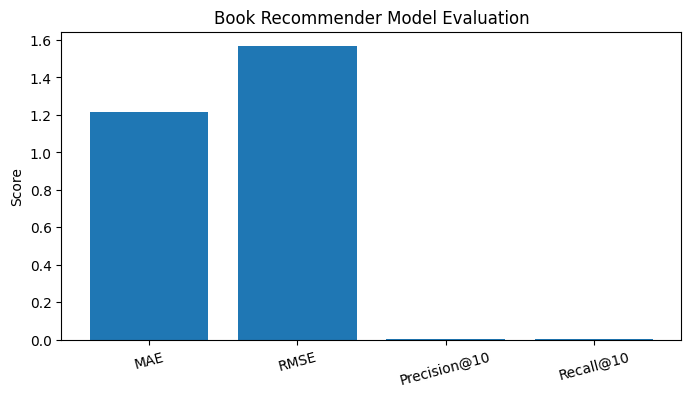

In [7]:
final_results = pd.DataFrame({
    "Evaluation Metric": [
        "MAE",
        "RMSE",
        "Precision@10",
        "Recall@10"
    ],
    "Score": [
        mae,
        rmse,
        average_precision,
        average_recall
    ]
})

display(final_results.round(4))

plt.figure(figsize=(8, 4))
plt.bar(
    final_results["Evaluation Metric"],
    final_results["Score"]
)
plt.title("Book Recommender Model Evaluation")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.show()

final_results.to_csv("final_results.csv", index=False)

 Create the complete Streamlit app

In [9]:
import pickle
import pandas as pd
import numpy as np

# Prepare book info metadata
book_info = Books[
    ["ISBN", "Book-Title", "Book-Author"]
].drop_duplicates("ISBN").copy()

book_info = book_info.fillna("Unknown")
book_info["ISBN"] = book_info["ISBN"].astype(str)

train_data = train_data.copy()
train_data["ISBN"] = train_data["ISBN"].astype(str)

# Save the simplified dataset for backup
with open("train_data.pkl", "wb") as f:
    pickle.dump(train_data, f)

# Save evaluation metrics
with open("metrics.pkl", "wb") as f:
    pickle.dump({
        "MAE": float(mae),
        "RMSE": float(rmse),
        "Precision@10": float(average_precision),
        "Recall@10": float(average_recall)
    }, f)

book_info.to_csv("book_info.csv", index=False)

print("All model files saved successfully!")

import os
print("\nSaved files:")
for filename in [
    "model_factors.pkl",
    "seen_by_user.pkl",
    "train_data.pkl",
    "metrics.pkl",
    "book_info.csv"
]:
    if os.path.exists(filename):
        print(filename, "—", os.path.getsize(filename), "bytes")
    else:
        print(filename, "— File not found")

All model files saved successfully!

Saved files:
model_factors.pkl — 20319072 bytes
seen_by_user.pkl — 999670 bytes
train_data.pkl — 3174704 bytes
metrics.pkl — 92 bytes
book_info.csv — 17749459 bytes


Create the complete Streamlit app


In [12]:
 %%writefile app.py
import pickle, numpy as np, pandas as pd, streamlit as st

st.set_page_config(page_title="Book Recommender", page_icon="📚", layout="wide")

@st.cache_resource
def load():
    model = pickle.load(open("model_factors.pkl", "rb"))
    seen = pickle.load(open("seen_by_user.pkl", "rb"))
    metrics = pickle.load(open("metrics.pkl", "rb"))
    info = pd.read_csv("book_info.csv", dtype={"ISBN": str}).fillna("Unknown")
    return model, seen, metrics, info

model, seen, metrics, info = load()
b_i_vec = model["b_i"].reindex(model["books"]).fillna(0).to_numpy()
B = model["V"].T / (np.linalg.norm(model["V"].T, axis=1, keepdims=True) + 1e-9)

def top_n(uid, n):
    u = model["u_idx"][uid]
    s = np.clip(model["mu"] + model["b_u"].get(uid, 0) + b_i_vec + model["U"][u] @ model["V"], 1, 10)
    out = []
    for j in np.argsort(-s):
        if model["books"][j] not in seen.get(uid, ()):
            out.append((model["books"][j], round(float(s[j]), 2)))
            if len(out) == n:
                break
    return pd.DataFrame(out, columns=["ISBN", "Predicted Rating"]).merge(info, on="ISBN", how="left")

def popular(n):  # cold-start fallback
    top = model["b_i"].sort_values(ascending=False).head(n)
    return pd.DataFrame({"ISBN": top.index}).merge(info, on="ISBN", how="left")

def similar(isbn, n):
    sims = B @ B[model["b_idx"][isbn]]
    top = np.argsort(-sims)[1:n + 1]
    return pd.DataFrame({"ISBN": model["books"][top],
                         "Cosine Similarity": sims[top].round(3)}).merge(info, on="ISBN", how="left")

st.title("📚 Book Recommender with Rating Prediction")
st.header("📊 Model Performance")
cols = st.columns(4)
for col, k in zip(cols, ["MAE", "RMSE", "Precision@10", "Recall@10"]):
    col.metric(k, f"{metrics[k]:.3f}")

n = st.sidebar.slider("Number of recommendations", 1, 20, 10)
tab1, tab2, tab3 = st.tabs(["Recommend for user", "Predict a rating", "Similar books"])

with tab1:
    uid_text = st.text_input("User ID")
    if st.button("Recommend Books", type="primary"):
        try:
            uid = int(uid_text)
            if uid in model["u_idx"]:
                df = top_n(uid, n)
            else:
                st.info("New user - showing popular books.")
                df = popular(n)
            show = [c for c in ["Book-Title", "Book-Author", "ISBN", "Predicted Rating"] if c in df]
            st.dataframe(df[show], use_container_width=True, hide_index=True)
        except ValueError:
            st.error("User ID must be a number.")

with tab2:
    u2 = st.text_input("User ID ", key="u2")
    i2 = st.text_input("Book ISBN", key="i2")
    if st.button("Predict rating"):
        try:
            uid = int(u2)
            if uid in model["u_idx"] and i2 in model["b_idx"]:
                p = (model["mu"] + model["b_u"].get(uid, 0) + model["b_i"].get(i2, 0)
                     + model["U"][model["u_idx"][uid]] @ model["V"][:, model["b_idx"][i2]])
                st.success(f"Predicted rating: {float(np.clip(p, 1, 10)):.2f} / 10")
            else:
                st.warning("User or book not in the trained model.")
        except ValueError:
            st.error("User ID must be a number.")

with tab3:
    i3 = st.text_input("Book ISBN", key="i3")
    if st.button("Find similar books"):
        if i3 in model["b_idx"]:
            st.dataframe(similar(i3, n), use_container_width=True, hide_index=True)
        else:
            st.warning("ISBN not in the trained model.")

Writing app.py


Launch Streamlit and generate the Colab URL


In [13]:
import os
import sys
import time
import subprocess
import urllib.request
from google.colab import output

# Stop an existing Streamlit process on port 8501, if present.
subprocess.run(
    "fuser -k 8501/tcp",
    shell=True,
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(2)

# Start Streamlit in the background.
log_file = open("streamlit.log", "w")

process = subprocess.Popen(
    [
        sys.executable, "-m", "streamlit", "run", "app.py",
        "--server.address=0.0.0.0",
        "--server.port=8501",
        "--server.headless=true",
        "--server.enableCORS=false",
        "--server.enableXsrfProtection=false",
        "--server.enableWebsocketCompression=false",
        "--browser.gatherUsageStats=false"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

# Wait for the app to respond.
ready = False

for attempt in range(20):
    time.sleep(1)
    try:
        with urllib.request.urlopen(
            "http://127.0.0.1:8501/_stcore/health",
            timeout=2
        ) as response:
            if response.status == 200:
                ready = True
                break
    except Exception:
        pass

if ready:
    print("Streamlit is running successfully!")
    url = output.eval_js("google.colab.kernel.proxyPort(8501)")
    print("\nOPEN YOUR PROJECT HERE:")
    print(url)
else:
    print("Streamlit did not start correctly.")
    print("Check the error log below:")
    print(open("streamlit.log").read())

Streamlit is running successfully!

OPEN YOUR PROJECT HERE:
https://8501-m-s-kkb-use1c1-19gm45uciamq0-c.us-east1-1.prod.colab.dev


In [ ]:
print(open("streamlit.log").read())